## 1. Imports and reproducibility

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from PIL import Image
from pathlib import Path
import warnings

np.random.seed(42)
tf.random.set_seed(42)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 2.4.6
TensorFlow: 2.21.0


## 2. Select and prepare an input image


Image shape: (256, 256) | intensity range: (np.float32(32.0), np.float32(255.0))


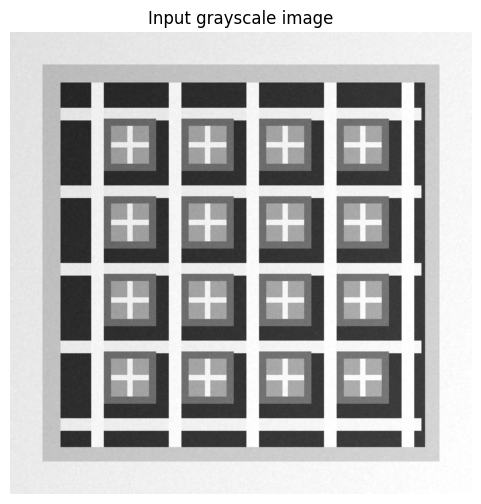

In [2]:
USE_UPLOADED_IMAGE = False

def make_architecture_image(size=256):
    image = np.full((size, size), 225, dtype=np.float32)
    image[18:238, 18:238] = 185
    image[28:230, 28:230] = 35
    # Repeated windows and structural beams
    for y in range(42, 215, 43):
        image[y:y+7, 28:228] = 225
    for x in range(45, 220, 43):
        image[28:230, x:x+7] = 235
    for y in range(48, 210, 43):
        for x in range(52, 215, 43):
            image[y:y+29, x:x+29] = 95
            image[y+4:y+25, x+4:x+25] = 150
            image[y+4:y+25, x+13:x+16] = 230
            image[y+13:y+16, x+4:x+25] = 230
    # Add a gentle gradient and deterministic texture
    yy, xx = np.mgrid[0:size, 0:size]
    image = np.clip(image + 0.08*xx + 0.04*yy, 0, 255)
    rng = np.random.default_rng(42)
    image = np.clip(image + rng.normal(0, 2, image.shape), 0, 255)
    return image.astype(np.uint8)

if USE_UPLOADED_IMAGE:
    try:
        from google.colab import files
        uploaded = files.upload()
        image_path = next(iter(uploaded))
    except Exception:
        image_path = input("Enter the path to your image: ").strip()
    input_image = Image.open(image_path).convert("L").resize((256, 256))
    gray_image = np.asarray(input_image, dtype=np.float32)
else:
    gray_image = make_architecture_image()

gray_image = gray_image.astype(np.float32)
print("Image shape:", gray_image.shape, "| intensity range:", (gray_image.min(), gray_image.max()))
plt.figure(figsize=(6, 6))
plt.imshow(gray_image, cmap="gray", vmin=0, vmax=255)
plt.title("Input grayscale image")
plt.axis("off")
plt.show()

## 3. Define five custom 3×3 kernels


In [3]:
kernels = {
    "Horizontal Edge (Sobel-X)": np.array([[-1, 0, 1],
                                            [-2, 0, 2],
                                            [-1, 0, 1]], dtype=np.float32),
    "Vertical Edge (Sobel-Y)": np.array([[-1, -2, -1],
                                         [ 0,  0,  0],
                                         [ 1,  2,  1]], dtype=np.float32),
    "Sharpen": np.array([[ 0, -1,  0],
                          [-1,  5, -1],
                          [ 0, -1,  0]], dtype=np.float32),
    "Box Blur": np.ones((3, 3), dtype=np.float32) / 9.0,
    "Emboss": np.array([[-2, -1, 0],
                         [-1,  1, 1],
                         [ 0,  1, 2]], dtype=np.float32)
}

for name, kernel in kernels.items():
    print(f"\n{name}\n{kernel}")


Horizontal Edge (Sobel-X)
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Vertical Edge (Sobel-Y)
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Sharpen
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Box Blur
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

Emboss
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]


## 4. Run convolution, ReLU, max pooling, and average pooling


In [4]:
image_tensor = tf.convert_to_tensor(gray_image[None, :, :, None], dtype=tf.float32)

def run_filter_pipeline(image_tensor, kernel):
    filter_tensor = tf.convert_to_tensor(kernel[:, :, None, None], dtype=tf.float32)
    raw = tf.nn.conv2d(image_tensor, filter_tensor, strides=1, padding="SAME")
    relu = tf.nn.relu(raw)
    max_pool = tf.nn.max_pool2d(relu, ksize=2, strides=2, padding="VALID")
    avg_pool = tf.nn.avg_pool2d(relu, ksize=2, strides=2, padding="VALID")
    return {
        "A — Raw Convolution": raw.numpy()[0, :, :, 0],
        "B — Post-ReLU": relu.numpy()[0, :, :, 0],
        "C — Max Pooling": max_pool.numpy()[0, :, :, 0],
        "D — Average Pooling": avg_pool.numpy()[0, :, :, 0]
    }

pipeline_results = {}
for name, kernel in kernels.items():
    pipeline_results[name] = run_filter_pipeline(image_tensor, kernel)

for name, stages in pipeline_results.items():
    print(name, {stage: arr.shape for stage, arr in stages.items()})

Horizontal Edge (Sobel-X) {'A — Raw Convolution': (256, 256), 'B — Post-ReLU': (256, 256), 'C — Max Pooling': (128, 128), 'D — Average Pooling': (128, 128)}
Vertical Edge (Sobel-Y) {'A — Raw Convolution': (256, 256), 'B — Post-ReLU': (256, 256), 'C — Max Pooling': (128, 128), 'D — Average Pooling': (128, 128)}
Sharpen {'A — Raw Convolution': (256, 256), 'B — Post-ReLU': (256, 256), 'C — Max Pooling': (128, 128), 'D — Average Pooling': (128, 128)}
Box Blur {'A — Raw Convolution': (256, 256), 'B — Post-ReLU': (256, 256), 'C — Max Pooling': (128, 128), 'D — Average Pooling': (128, 128)}
Emboss {'A — Raw Convolution': (256, 256), 'B — Post-ReLU': (256, 256), 'C — Max Pooling': (128, 128), 'D — Average Pooling': (128, 128)}


## 5. Required 5 × 4 comparative visualization grid


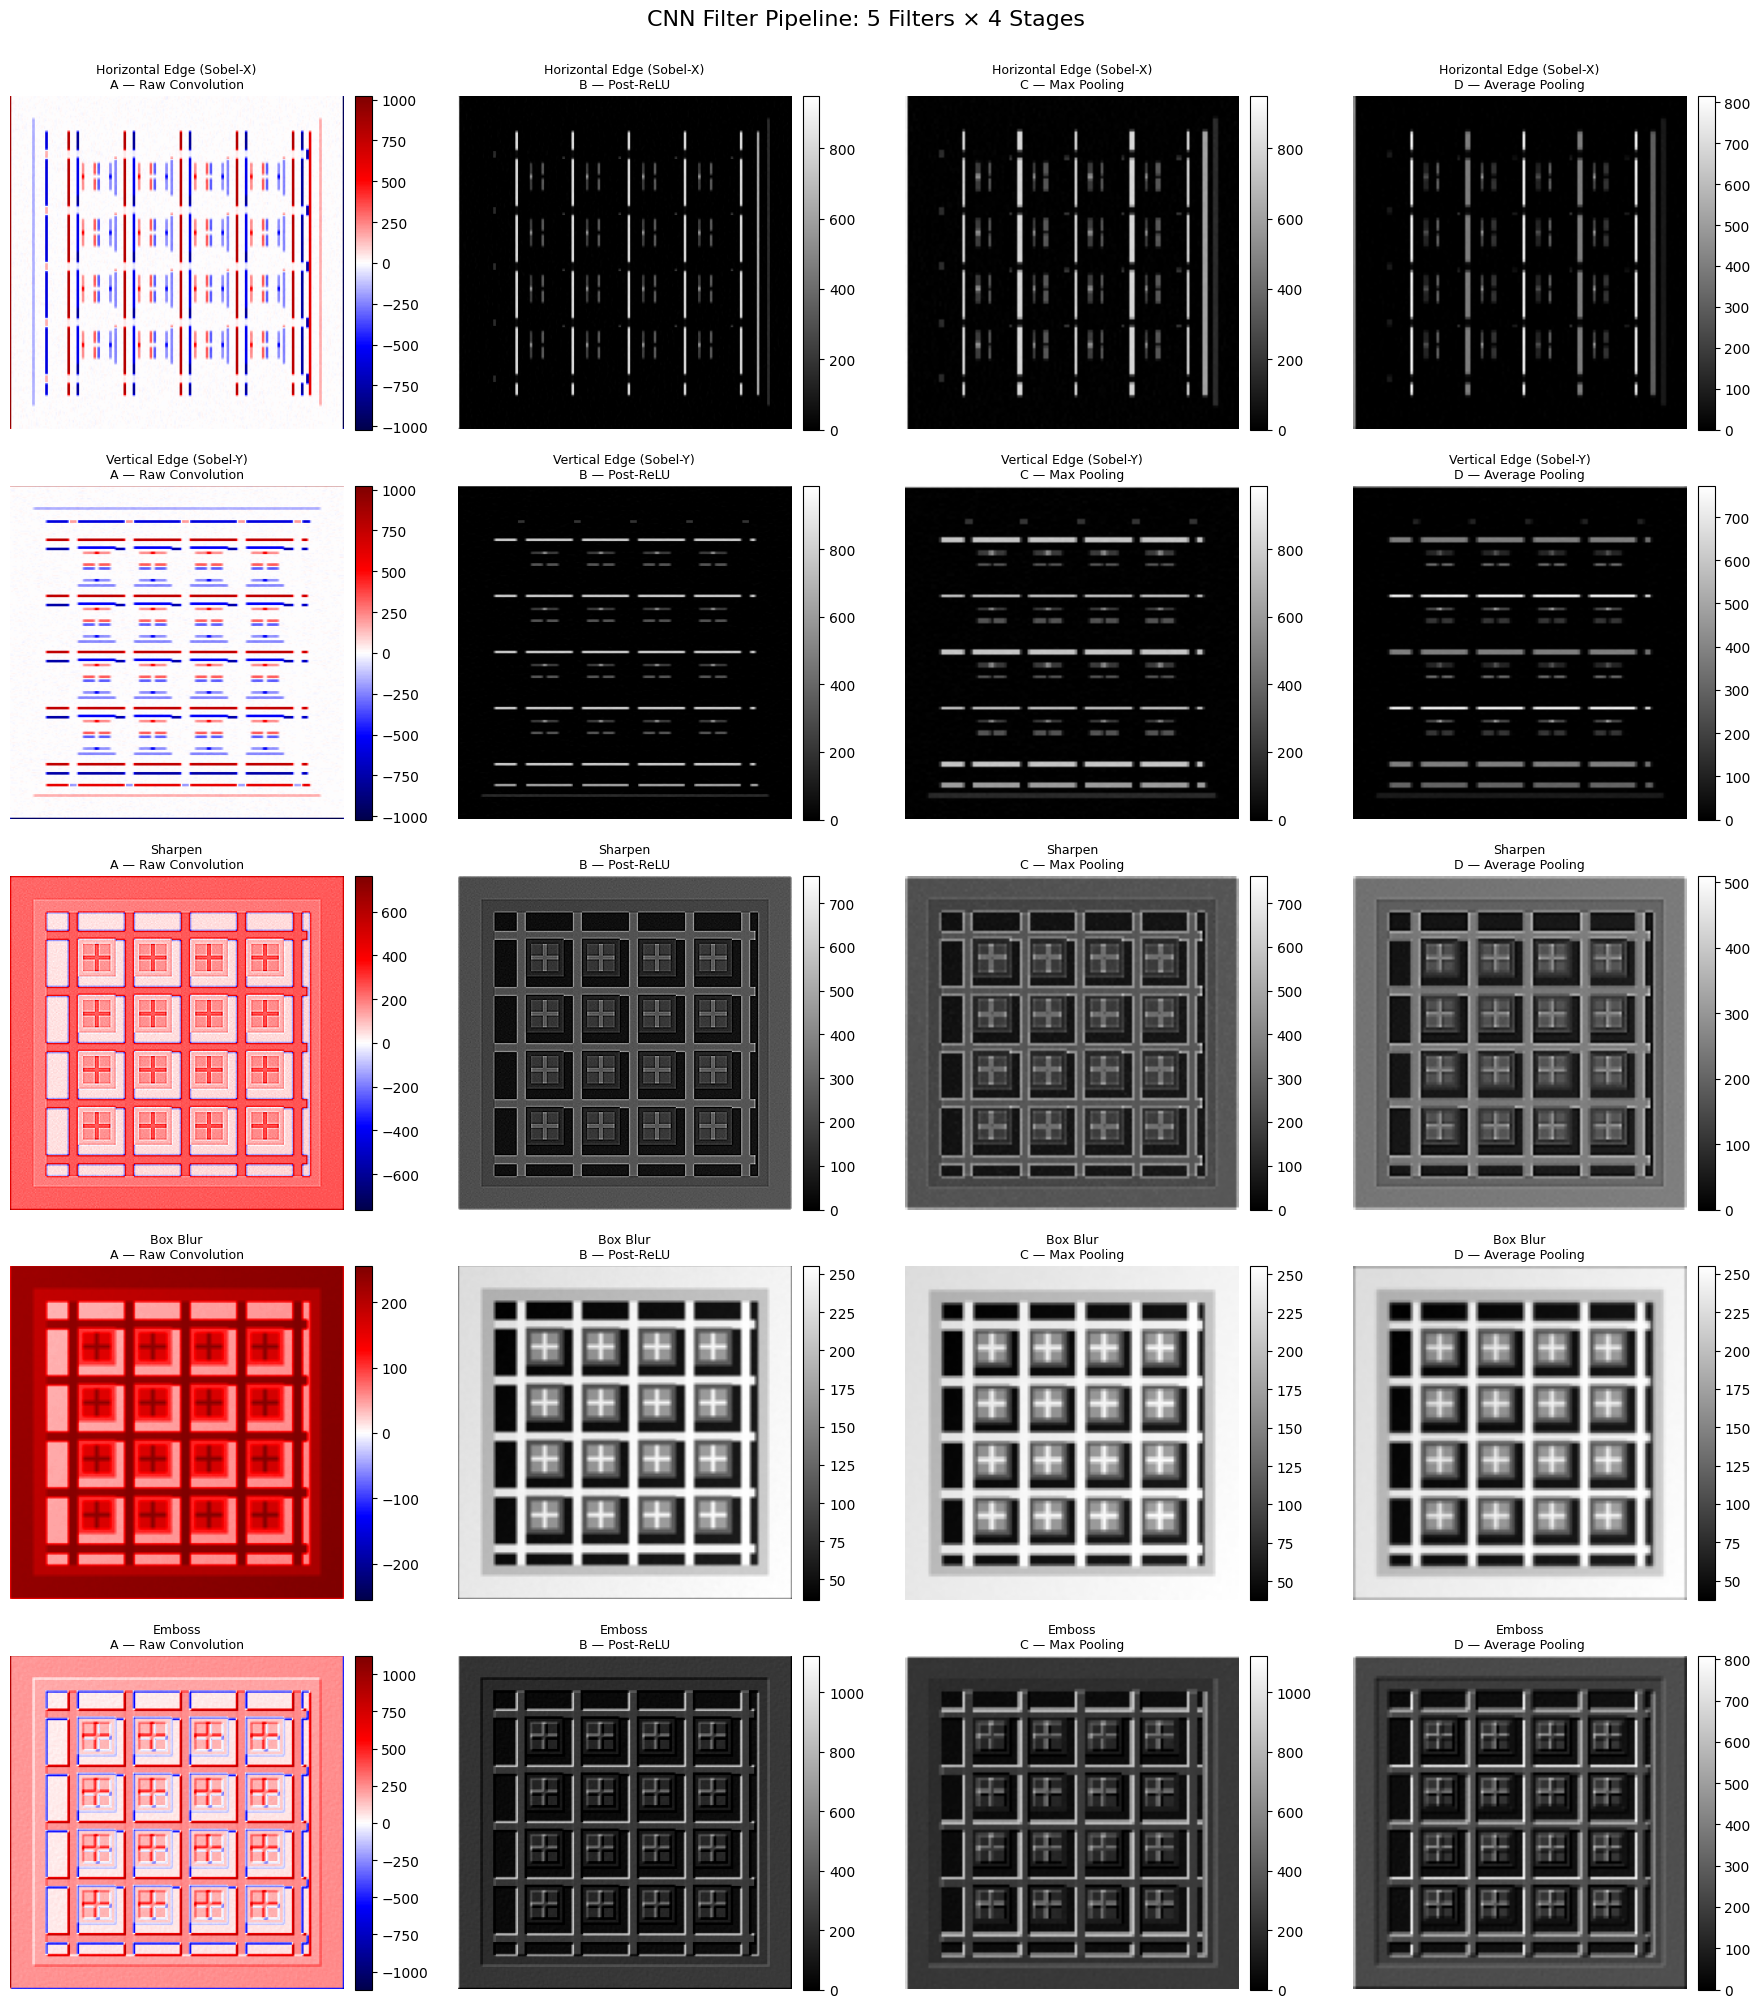

In [5]:
stage_names = ["A — Raw Convolution", "B — Post-ReLU", "C — Max Pooling", "D — Average Pooling"]
fig, axes = plt.subplots(5, 4, figsize=(18, 20))
for row, (filter_name, stages) in enumerate(pipeline_results.items()):
    for col, stage_name in enumerate(stage_names):
        ax = axes[row, col]
        data = stages[stage_name]
        if col == 0:
            vmax = max(float(np.max(np.abs(data))), 1e-6)
            im = ax.imshow(data, cmap="seismic", vmin=-vmax, vmax=vmax)
        else:
            im = ax.imshow(data, cmap="gray")
        ax.set_title(f"{filter_name}\n{stage_name}", fontsize=9)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
plt.suptitle("CNN Filter Pipeline: 5 Filters × 4 Stages", fontsize=16, y=1.002)
plt.tight_layout()
plt.show()

## 6. Numerical evidence from the feature maps


In [6]:
records = []
for filter_name, stages in pipeline_results.items():
    for stage_name, data in stages.items():
        records.append({
            "Filter": filter_name,
            "Stage": stage_name,
            "Minimum": float(np.min(data)),
            "Maximum": float(np.max(data)),
            "Mean": float(np.mean(data)),
            "Std. Dev.": float(np.std(data)),
            "Shape": str(data.shape)
        })
feature_statistics = pd.DataFrame(records)
display(feature_statistics.round(3))

,Filter,Stage,Minimum,Maximum,Mean,Std. Dev.,Shape
0,Horizontal Edge (Sobel-X),A — Raw Convolution,-1020.000,948.000,0.318,208.429,"(256, 256)"
1,Horizontal Edge (Sobel-X),B — Post-ReLU,0.000,948.000,37.329,147.642,"(256, 256)"
2,Horizontal Edge (Sobel-X),C — Max Pooling,0.000,948.000,62.256,183.869,"(128, 128)"
3,Horizontal Edge (Sobel-X),D — Average Pooling,0.000,815.000,37.329,123.698,"(128, 128)"
4,Vertical Edge (Sobel-Y),A — Raw Convolution,-1020.000,986.000,0.159,197.733,"(256, 256)"
5,Vertical Edge (Sobel-Y),B — Post-ReLU,0.000,986.000,35.051,141.341,"(256, 256)"
6,Vertical Edge (Sobel-Y),C — Max Pooling,0.000,986.000,62.600,183.562,"(128, 128)"
7,Vertical Edge (Sobel-Y),D — Average Pooling,0.000,771.000,35.051,112.145,"(128, 128)"
8,Sharpen,A — Raw Convolution,-365.000,761.000,178.008,129.782,"(256, 256)"
9,Sharpen,B — Post-ReLU,0.000,761.000,185.186,114.859,"(256, 256)"


## 7. Part II — CNN architectures and manual parameter audit


Formula:

\[
P_{conv}=(K_h K_w C_{in}+1)C_{out}
\]

The `+1` is one bias per output filter.

In [7]:
def conv_parameter_count(kernel_size, input_channels, output_channels):
    return (kernel_size * kernel_size * input_channels + 1) * output_channels

audit_rows = []
manual_totals = {}
for model_name, kernel_size, pooling_name in [
    ("Model A (Standard)", 3, "Max Pooling"),
    ("Model B (Large Kernel)", 5, "Average Pooling")
]:
    conv1 = conv_parameter_count(kernel_size, 3, 5)
    conv2 = conv_parameter_count(kernel_size, 5, 10)
    total = conv1 + conv2
    manual_totals[model_name] = total
    audit_rows.append({
        "Model": model_name,
        "Kernel": f"{kernel_size}×{kernel_size}",
        "Pooling": pooling_name,
        "Conv1 parameters": conv1,
        "Conv2 parameters": conv2,
        "Total trainable parameters": total
    })

audit_table = pd.DataFrame(audit_rows)
display(audit_table)
print("Model A calculation:")
print("Conv1 = (3×3×3 + 1)×5 = 140")
print("Conv2 = (3×3×5 + 1)×10 = 460? No: (45 + 1)×10 = 460")
print("Total Model A = 140 + 460 =", manual_totals["Model A (Standard)"])
print("\nModel B calculation:")
print("Conv1 = (5×5×3 + 1)×5 = 380")
print("Conv2 = (5×5×5 + 1)×10 = 1260")
print("Total Model B = 380 + 1260 =", manual_totals["Model B (Large Kernel)"])
increase_percent = (manual_totals["Model B (Large Kernel)"] - manual_totals["Model A (Standard)"]) / manual_totals["Model A (Standard)"] * 100
print(f"Percentage increase from A to B = {increase_percent:.2f}%")

,Model,Kernel,Pooling,Conv1 parameters,Conv2 parameters,Total trainable parameters
0,Model A (Standard),3×3,Max Pooling,140,460,600
1,Model B (Large Kernel),5×5,Average Pooling,380,1260,1640


Model A calculation:
Conv1 = (3×3×3 + 1)×5 = 140
Conv2 = (3×3×5 + 1)×10 = 460? No: (45 + 1)×10 = 460
Total Model A = 140 + 460 = 600

Model B calculation:
Conv1 = (5×5×3 + 1)×5 = 380
Conv2 = (5×5×5 + 1)×10 = 1260
Total Model B = 380 + 1260 = 1640
Percentage increase from A to B = 173.33%


### 7.1 Build both Keras models and compare summary counts


In [8]:
def build_cnn(kernel_size, pooling="max", model_name="cnn"):
    Pool = layers.MaxPooling2D if pooling == "max" else layers.AveragePooling2D
    inputs = layers.Input(shape=(32, 32, 3), name="input_rgb")
    x = layers.Conv2D(5, kernel_size, padding="same", activation="relu", name="conv1")(inputs)
    x = Pool(pool_size=(2, 2), strides=2, name="pool1")(x)
    x = layers.Conv2D(10, kernel_size, padding="same", activation="relu", name="conv2")(x)
    x = Pool(pool_size=(2, 2), strides=2, name="pool2")(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    outputs = layers.Dense(10, activation="softmax", name="class_output")(x)
    return models.Model(inputs, outputs, name=model_name)

model_a = build_cnn(3, "max", "Model_A_Standard")
model_b = build_cnn(5, "avg", "Model_B_Large_Kernel")

print("MODEL A SUMMARY")
model_a.summary()
print("\nMODEL B SUMMARY")
model_b.summary()

def framework_parameter_count(model):
    return int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))

for model, label in [(model_a, "Model A"), (model_b, "Model B")]:
    print(f"{label} framework trainable parameters: {framework_parameter_count(model):,}")

MODEL A SUMMARY


Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_rgb (InputLayer)          │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

Model A framework trainable parameters: 710
Model B framework trainable parameters: 1,750


### 7.2 Full parameter audit including the classifier


In [9]:
def complete_manual_count(kernel_size):
    conv1 = conv_parameter_count(kernel_size, 3, 5)
    conv2 = conv_parameter_count(kernel_size, 5, 10)
    dense = (10 + 1) * 10
    return conv1, conv2, dense, conv1 + conv2 + dense

complete_rows = []
for label, k, model in [
    ("Model A (Standard)", 3, model_a),
    ("Model B (Large Kernel)", 5, model_b)
]:
    c1, c2, dense, total = complete_manual_count(k)
    framework = framework_parameter_count(model)
    complete_rows.append({
        "Model": label,
        "Conv1 manual": c1,
        "Conv2 manual": c2,
        "Dense manual": dense,
        "Total manual": total,
        "Keras trainable": framework,
        "Match": total == framework
    })
display(pd.DataFrame(complete_rows))
assert all(row["Match"] for row in complete_rows), "Manual and Keras counts do not match."
print("Both hand calculations match the framework's trainable parameter counts.")

,Model,Conv1 manual,Conv2 manual,Dense manual,Total manual,Keras trainable,Match
0,Model A (Standard),140,460,110,710,710,True
1,Model B (Large Kernel),380,1260,110,1750,1750,True


Both hand calculations match the framework's trainable parameter counts.


### 7.3 Parameter calculations, step by step

**Model A — 3×3 kernels, Max Pooling**
- Conv1: input channels = 3, output filters = 5  
  \((3×3×3+1)×5=(27+1)×5=140\)
- Conv2: input channels = 5, output filters = 10  
  \((3×3×5+1)×10=(45+1)×10=460\)
- Convolution subtotal = \(140+460=600\)
- GAP = 0 parameters
- Dense(10): \((10+1)×10=110\)
- **Total trainable parameters = 600+110 = 710**

**Model B — 5×5 kernels, Average Pooling**
- Conv1: \((5×5×3+1)×5=(75+1)×5=380\)
- Conv2: \((5×5×5+1)×10=(125+1)×10=1260\)
- Convolution subtotal = \(380+1260=1640\)
- GAP = 0 parameters
- Dense(10) = 110
- **Total trainable parameters = 1640+110 = 1750**

**Exact increase in total trainable parameters (including the Dense classifier):**

\[
\\frac{1750-710}{710}×100=146.48\\%
\]

For reference, if comparing only the two convolution layers and excluding the identical Dense classifier, the increase is \((1640-600)/600×100=173.33\\%\). The assignment's wording says total trainable parameters, so **146.48%** is the full-model answer.

## 8. Part III — Critical Thinking & Viva Defense


### Question 1 — ReLU “Blackout” Effect & Activation Alternatives

**Which regions turn black, and why?** In the horizontal-edge row and vertical-edge row, every pixel whose raw convolution response is negative becomes exactly zero in Stage B. These are regions where the local intensity transition has the opposite polarity to the filter's positive direction. For example, a bright-to-dark transition can produce a negative response while the reverse dark-to-bright transition produces a positive response. Flat regions ideally produce values near zero for edge kernels. Thus, the zero/black areas in Stage B correspond to negative-polarity responses and near-zero responses; ReLU removes the negative values using \(f(x)=\max(0,x)\).

**Leaky ReLU:** \(f(x)=x\) for \(x≥0\), and \(0.1x\) for \(x<0\). Negative responses remain visible but are reduced to one tenth of their original magnitude. The output is no longer completely black for negative responses.

**Sigmoid:** \(\sigma(x)=1/(1+e^{-x})\). Values are mapped into (0,1), so negative responses become values below 0.5 rather than zero. Large positive and negative magnitudes saturate near 1 and 0. Unlike ReLU, sigmoid compresses the dynamic range and is not zero-preserving.

### Question 2 — Max Pooling vs. Average Pooling Information Retention

In Stage C, max pooling selects the largest value in each 2×2 block. A strong positive edge or sharpened response can therefore survive if it is the largest activation in its local window. In Stage D, average pooling averages all four values, so an isolated strong response is diluted by neighboring lower values. This is why narrow, high-contrast responses in the Sharpen and edge rows can appear stronger under max pooling and smoother/weaker under average pooling.

**Dark ink on a pure white background:** If the goal is to preserve the dark strokes themselves as low-valued pixels, average pooling generally retains their influence in the pooled value, whereas max pooling over ordinary grayscale intensities tends to choose the bright white background and can erase a thin dark stroke. If the image is inverted (ink high, background low), max pooling is better at retaining the strongest ink activation. The answer depends on intensity polarity and whether the feature of interest is represented by high or low values.

### Question 3 — Parameter Explosion & Receptive Field Equivalence

For the convolutional layers:
- Model A = \(140+460=600\) convolution parameters.
- Model B = \(380+1260=1640\) convolution parameters.

Including the identical Dense(10) classifier (110 parameters), total trainable parameters are 710 for Model A and 1750 for Model B. Therefore, the exact increase in **total model trainable parameters** is:

\[
\frac{1750-710}{710}\times100=146.48\%
\]

(If only the convolution layers are compared, the increase is 173.33%.)

A stack of two stride-1 3×3 convolutions has an effective receptive field of \(3+(3-1)=5\), so **two 3×3 layers** provide a 5×5 receptive field, assuming no pooling between them.

For a comparison from 5 input channels to 10 output channels, using 5 intermediate channels:
- One 5×5 convolution: \((5×5×5+1)×10=1260\) parameters.
- Two 3×3 convolutions (5→5, then 5→10): \((3×3×5+1)×5+(3×3×5+1)×10=230+460=690\).
- **Parameters saved = \(1260-690=570\), or 45.24%** of the single 5×5 layer's parameters.

The parameter saving depends on the chosen intermediate width (5 channels); receptive-field equivalence alone does not determine a unique parameter saving.

### Question 4 — Operation Commutativity (Order Invariance)

For max pooling, the two orders are identical when the same max operation is used on a patch:

\[
\max(\operatorname{ReLU}(x_i))=\max(\max(0,x_i))=\max(0,\max(x_i))
=\operatorname{ReLU}(\max(x_i)).
\]

Example 2×2 patch after convolution:

\[
\begin{bmatrix}-4 & 2\\-1 & -3\end{bmatrix}
\]

**Conv → ReLU → MaxPool:** ReLU gives \([ [0,2],[0,0] ]\); max pooling gives 2.

**Conv → MaxPool → ReLU:** max pooling first gives 2; ReLU gives 2. The results are identical. This holds because ReLU is monotonic and max pooling selects the maximum.

**Efficiency implication:** Pooling before ReLU does not change the max-pooled result, and an implementation may fuse or reorder these operations. However, this equivalence is specific to max pooling and ReLU; it should not be generalized to average pooling, which can differ when negative values are present.

### Question 5 — Diagnosing Filter Redundancy (Debugging Scenario)

If all five first-layer filters learn nearly identical feature maps, the filters are not learning diverse detectors. Two plausible causes and fixes are:

1. **Identical or overly similar initialization:** If filters start with the same weights, they receive similar gradients and can remain redundant. **Fix:** use a variance-scaled random initializer such as He initialization for ReLU networks (`kernel_initializer="he_normal"`), and ensure each filter is initialized independently.
2. **Optimization/gradient problem (for example, an unsuitable learning rate or dead ReLUs):** A learning rate that is too high can destabilize updates; one that is too low can make filters change negligibly. Dead ReLUs produce zero gradients for units that remain on the negative side. **Fix:** inspect activation distributions and gradient norms, use a sensible learning rate (for example, start with Adam at 0.001 and tune on validation data), and consider Leaky ReLU if many units are inactive.

Other checks include verifying that the input data is normalized, labels are correct, and the filters are not accidentally tied/shared in code.